# Data Validation and Quality Assessment
## Mumbai Rental Property Dataset

### 1. Introduction

This notebook evaluates the quality, consistency, and reliability of the Mumbai rental property dataset after data cleaning.

The purpose is not to repeat the cleaning process, but to independently assess its results and identify potential limitations.

### Research Questions

1. Is the cleaned dataset reliable?
2. How much information was lost during data cleaning?
3. Did the cleaning process introduce potential bias?

### Validation Methodology

Our validation will cover:

- Dataset structure and data types
- Missing values and duplicates
- Logical consistency and invalid values
- Outlier detection
- Information loss during cleaning
- Comparison of original and cleaned distributions
- Potential selection bias

### Expected Outcome

A reproducible validation report identifying data quality issues, cleaning impacts, and recommendations for further analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
# Identify the current working directory
print("Current working directory:")
print(Path.cwd())

# Locate the cleaned data folder
possible_paths = [
    Path("data/cleaned"),
    Path("../data/cleaned")
]

cleaned_folder = None

for folder in possible_paths:
    if folder.is_dir():
        cleaned_folder = folder.resolve()
        break

if cleaned_folder is not None:
    print("\nCleaned data folder:", cleaned_folder)
    print("\nAvailable CSV files:")

    for file in sorted(cleaned_folder.glob("*.csv")):
        print("-", file.name)
else:
    print("Cleaned data folder not found.")

Current working directory:
c:\Users\Akanksha\Documents\IAAC\CLASSES\AI Labs\Group3-day1assignment\Group3-day1assignment\notebooks

Cleaned data folder: C:\Users\Akanksha\Documents\IAAC\CLASSES\AI Labs\Group3-day1assignment\Group3-day1assignment\data\cleaned

Available CSV files:
- mumbai_rentals_cleaned.csv
- mumbai_rentals_cleaning_audit.csv
- mumbai_rentals_filtered.csv
- mumbai_rentals_refactored.csv


In [3]:
# Load the cleaned dataset

dataset_file = cleaned_folder / "mumbai_rentals_refactored.csv"

if not dataset_file.exists():
    raise FileNotFoundError(
        f"Dataset not found: {dataset_file}"
    )

df_clean = pd.read_csv(dataset_file)

print("Dataset loaded successfully!")

print("\nNumber of rows:", df_clean.shape[0])
print("Number of columns:", df_clean.shape[1])

display(df_clean.head())

Dataset loaded successfully!

Number of rows: 20294
Number of columns: 22


,Title,Price,Area,BHK,Bathrooms,Furnished,Balconies,Floor,Ownership,Facing,...,Property Type,Location,Year of Construction,Is Luxury,Description,Property Image,Invalid_Price,Suspicious_Area,Price_per_m2,Suspicious_Price
0,1BHK Multistorey Apartment for Rent in Bandra ...,70000.0,750.0,1.0,1.0,Furnished,NaN,7.0,Unknown,South -West,...,Apartment,Mumbai,2012.0,F,"1 BHK, Multistorey Apartment is available for ...",67249079_2_PropertyImage345-4855396928822.jpg,False,False,93.333333,False
1,3BHK Multistorey Apartment for Rent in Lodha N...,140000.0,1980.0,3.0,4.0,Unfurnished,4.0,21.0,Unknown,East,...,Apartment,Mumbai,1994.0,F,"3 BHK, Multistorey Apartment is available for ...",66155783_5_hatsAppImage20230217at13.56.28.jpeg,False,False,70.707071,False
2,3BHK Multistorey Apartment for Rent in Lodha P...,190000.0,1592.0,3.0,3.0,Unfurnished,1.0,20.0,Unknown,North - East,...,Apartment,Mumbai,NaN,F,"3 BHK, Multistorey Apartment is available for ...",66686709_1_HOTO20230407165614.jpg,False,False,119.346734,False
3,3BHK Multistorey Apartment for Rent in Rustomj...,110000.0,1305.0,3.0,3.0,Unfurnished,3.0,11.0,Freehold,West,...,Apartment,Mumbai,2010.0,F,"3 BHK, Multistorey Apartment is available for ...",67875387_1_PropertyImage559-8385323621333.jpg,False,False,84.291188,False
4,3BHK Multistorey Apartment for Rent in DLH The...,140000.0,1350.0,3.0,3.0,Unfurnished,NaN,29.0,Freehold,East,...,Apartment,Mumbai,2000.0,F,"3 BHK, Multistorey Apartment is available for ...",66670931_3_PropertyImage314-6685675359874.jpg,False,False,103.703704,False


In [4]:
# Inspect dataset structure

print("Dataset information:")
df_clean.info()

print("\nColumn names:")
print(df_clean.columns.tolist())

print("\nData types:")
display(
    df_clean.dtypes.to_frame(name="Data Type")
)

print("\nDescriptive statistics:")
display(df_clean.describe(include="all").T)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20294 entries, 0 to 20293
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Title                 20294 non-null  str    
 1   Price                 20195 non-null  float64
 2   Area                  19595 non-null  float64
 3   BHK                   20051 non-null  float64
 4   Bathrooms             20198 non-null  float64
 5   Furnished             20208 non-null  str    
 6   Balconies             9255 non-null   float64
 7   Floor                 19430 non-null  float64
 8   Ownership             20294 non-null  str    
 9   Facing                20294 non-null  str    
 10  Amenities             20294 non-null  str    
 11  Transaction Type      20289 non-null  str    
 12  Property Type         20294 non-null  str    
 13  Location              20294 non-null  str    
 14  Year of Construction  14304 non-null  float64
 15  Is Luxury

,Data Type
Title,str
Price,float64
Area,float64
BHK,float64
Bathrooms,float64
Furnished,str
Balconies,float64
Floor,float64
Ownership,str
Facing,str



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Title,20294,7035,2BHK Multistorey Apartment for Rent in Bandra ...,193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,20195.0,NaN,NaN,NaN,122968.801089,565711.862207,1800.0,44000.0,70000.0,130000.0,40000000.0
Area,19595.0,NaN,NaN,NaN,1258.704823,816.500573,2.0,750.0,1080.0,1500.0,15000.0
BHK,20051.0,NaN,NaN,NaN,2.221635,0.936728,1.0,2.0,2.0,3.0,7.0
Bathrooms,20198.0,NaN,NaN,NaN,2.334092,0.953427,1.0,2.0,2.0,3.0,10.0
Furnished,20208,3,Semi-Furnished,8752,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Balconies,9255.0,NaN,NaN,NaN,1.845489,1.041761,1.0,1.0,2.0,2.0,10.0
Floor,19430.0,NaN,NaN,NaN,9.928152,9.4505,-2.0,4.0,7.0,13.0,77.0
Ownership,20294,5,Unknown,17652,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Facing,20294,9,East,9951,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Calculate missing values

missing_report = pd.DataFrame({
    "Missing Count": df_clean.isna().sum(),
    "Missing Percentage": (
        df_clean.isna().mean() * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    "Missing Percentage",
    ascending=False
)

display(missing_report)

print(
    "Total missing cells:",
    df_clean.isna().sum().sum()
)

,Missing Count,Missing Percentage
Balconies,11039,54.40
Year of Construction,5990,29.52
Property Image,2730,13.45
Floor,864,4.26
Price_per_m2,728,3.59
Area,699,3.44
BHK,243,1.20
Price,99,0.49
Bathrooms,96,0.47
Furnished,86,0.42


Total missing cells: 22579


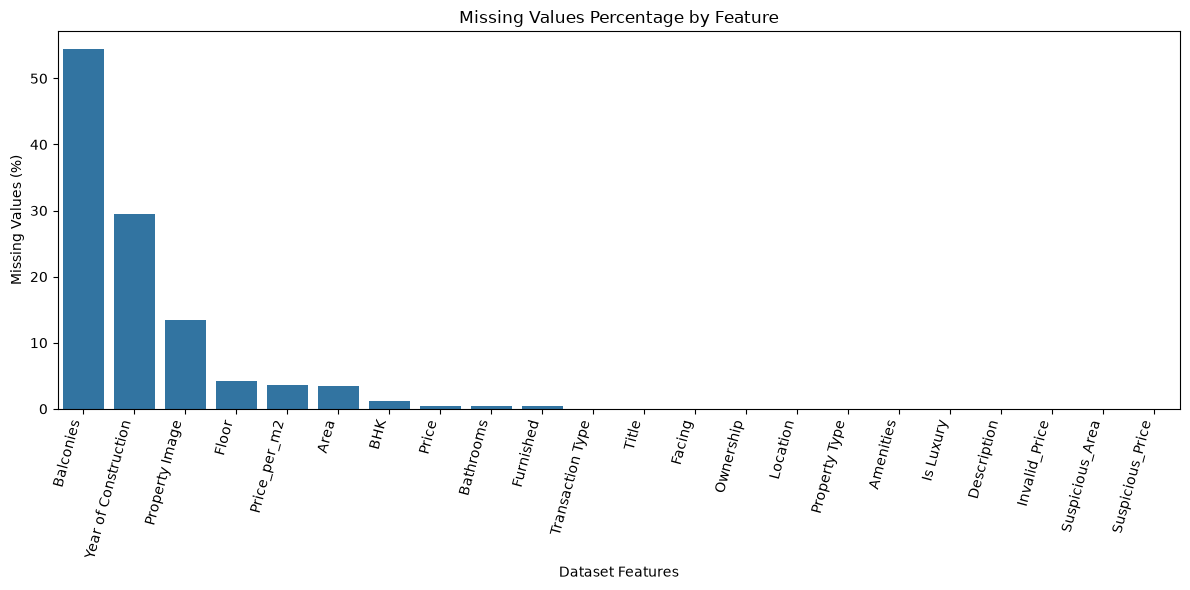

In [6]:
# Visualize missing values by column

plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing_report.index,
    y=missing_report["Missing Percentage"]
)

plt.title("Missing Values Percentage by Feature")
plt.xlabel("Dataset Features")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

In [7]:
# Check for exact duplicate records

total_records = len(df_clean)

duplicate_count = df_clean.duplicated().sum()

duplicate_percentage = (
    duplicate_count / total_records * 100
    if total_records > 0 else 0
)

print("Total records:", total_records)
print("Duplicate records:", duplicate_count)
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

# Create a validation summary
duplicate_report = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Duplicate Records",
        "Unique Records",
        "Duplicate Percentage (%)"
    ],
    "Value": [
        total_records,
        duplicate_count,
        total_records - duplicate_count,
        round(duplicate_percentage, 2)
    ]
})

display(duplicate_report)

# Display duplicate rows if any exist
if duplicate_count > 0:
    display(df_clean[df_clean.duplicated(keep=False)].head(10))
else:
    print("No exact duplicate records detected.")

Total records: 20294
Duplicate records: 0
Duplicate percentage: 0.00%


,Metric,Value
0,Total Records,20294.0
1,Duplicate Records,0.0
2,Unique Records,20294.0
3,Duplicate Percentage (%),0.0


No exact duplicate records detected.


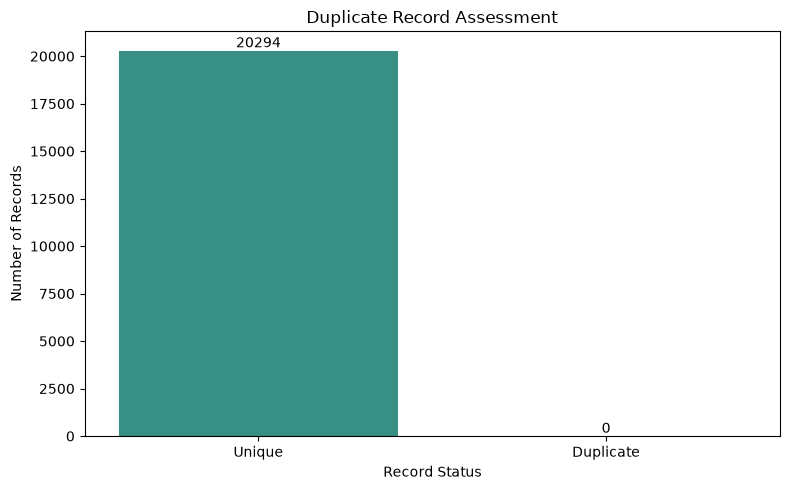

In [8]:
# Visualize duplicate vs non-duplicate records

duplicate_chart = pd.DataFrame({
    "Record Status": ["Unique", "Duplicate"],
    "Count": [
        total_records - duplicate_count,
        duplicate_count
    ]
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=duplicate_chart,
    x="Record Status",
    y="Count",
    hue="Record Status",
    palette=["#2A9D8F", "#E76F51"],
    legend=False
)

plt.title("Duplicate Record Assessment")
plt.xlabel("Record Status")
plt.ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.show()

In [9]:
# Define numerical validation rules

validation_rules = {
    "Price": lambda x: x <= 0,
    "Area": lambda x: x <= 0,
    "BHK": lambda x: x < 0,
    "Bathrooms": lambda x: x < 0,
    "Balconies": lambda x: x < 0
}

validation_results = []

for column, rule in validation_rules.items():

    if column in df_clean.columns:

        values = pd.to_numeric(
            df_clean[column],
            errors="coerce"
        )

        invalid_numeric = (
            df_clean[column].notna() & values.isna()
        )

        invalid_logical = rule(values).fillna(False)

        invalid_count = (
            invalid_numeric | invalid_logical
        ).sum()

        validation_results.append({
            "Feature": column,
            "Invalid Records": int(invalid_count),
            "Invalid Percentage": round(
                invalid_count / len(df_clean) * 100, 2
            ) if len(df_clean) else 0
        })

    else:
        print(f"Column not found: {column}")

consistency_report = pd.DataFrame(validation_results)

display(consistency_report)

,Feature,Invalid Records,Invalid Percentage
0,Price,0,0.0
1,Area,0,0.0
2,BHK,0,0.0
3,Bathrooms,0,0.0
4,Balconies,0,0.0


### Logical Consistency — Findings

The validation checks identified no invalid values across the five numerical features examined: Price, Area, BHK, Bathrooms, and Balconies.

All tested records satisfy the defined numerical constraints.

However, passing these checks does not guarantee complete data reliability. Extreme values, relationships between variables, and potential cleaning bias still require further investigation.

**Conclusion:** The cleaned dataset passed the initial logical consistency checks.

In [10]:
# Detect potential outliers using the IQR method

outlier_results = []

for column in ["Price", "Area"]:

    values = pd.to_numeric(
        df_clean[column],
        errors="coerce"
    ).dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (values < lower_bound) |
        (values > upper_bound)
    )

    outlier_results.append({
        "Feature": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": int(outliers.sum()),
        "Outlier Percentage": round(
            outliers.mean() * 100, 2
        )
    })

outlier_report = pd.DataFrame(outlier_results)

display(outlier_report)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Price,-85000.0,259000.0,1625,8.05
1,Area,-375.0,2625.0,1095,5.59


## 7. Outlier Detection and Assessment

### Objective

Outliers are observations that differ substantially from the majority of the dataset.

In rental property data, unusually high prices or large property areas may represent luxury properties, data entry errors, or exceptional cases.

### Research Questions

1. Are there extreme rental prices?
2. Are there unusually large property areas?
3. How many observations are flagged as potential outliers?
4. Could these observations influence statistical results?

### Methodology

We use the Interquartile Range (IQR) method:

- Q1: 25th percentile
- Q3: 75th percentile
- IQR = Q3 - Q1
- Lower Bound = Q1 - 1.5 × IQR
- Upper Bound = Q3 + 1.5 × IQR

Observations outside these bounds are flagged for further investigation, not automatically removed.

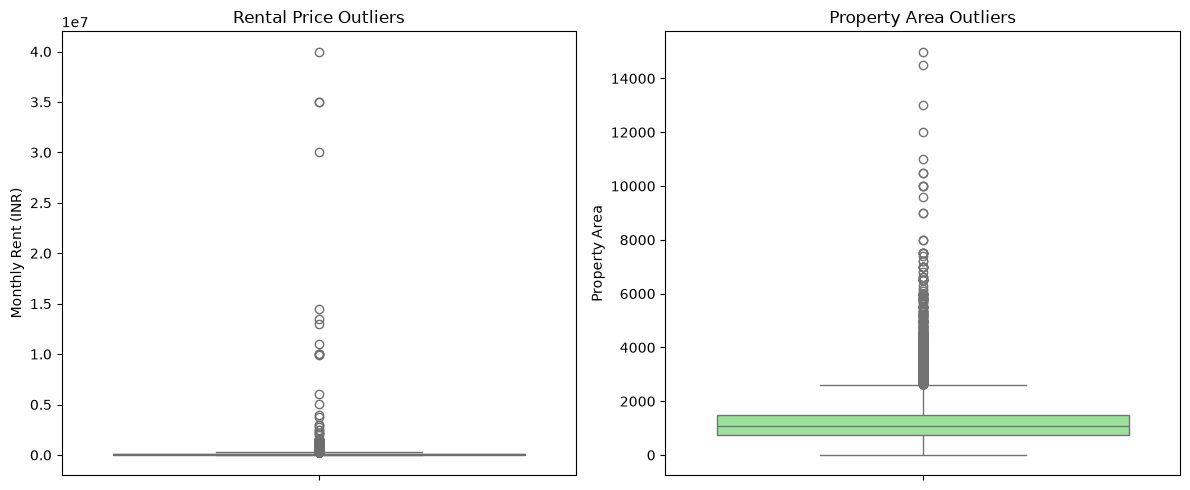

In [11]:
# Visualize potential outliers

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    y=pd.to_numeric(df_clean["Price"], errors="coerce"),
    ax=axes[0],
    color="skyblue"
)

axes[0].set_title("Rental Price Outliers")
axes[0].set_ylabel("Monthly Rent (INR)")

sns.boxplot(
    y=pd.to_numeric(df_clean["Area"], errors="coerce"),
    ax=axes[1],
    color="lightgreen"
)

axes[1].set_title("Property Area Outliers")
axes[1].set_ylabel("Property Area")

plt.tight_layout()
plt.show()

In [2]:
print("Current working directory:", Path.cwd())

raw_files = list(
    Path.cwd().rglob("Mumbai_property_details.csv")
)

print("Original dataset candidates:", raw_files)

if not raw_files:
    print("Original CSV not found in the current project.")
else:
    raw_file = raw_files[0]
    df_raw = pd.read_csv(raw_file)

    print("Original dataset loaded successfully!")
    print("Original dataset shape:", df_raw.shape)
    print("Cleaned dataset shape:", df_clean.shape)

NameError: name 'Path' is not defined

In [1]:
# Calculate data retention statistics

original_rows = len(df_raw)
cleaned_rows = len(df_clean)

rows_removed = original_rows - cleaned_rows

retention_percentage = (
    cleaned_rows / original_rows * 100
    if original_rows > 0 else 0
)

removal_percentage = (
    rows_removed / original_rows * 100
    if original_rows > 0 else 0
)

retention_report = pd.DataFrame({
    "Metric": [
        "Original Records",
        "Cleaned Records",
        "Net Records Removed",
        "Retention Percentage",
        "Removal Percentage"
    ],
    "Value": [
        original_rows,
        cleaned_rows,
        rows_removed,
        round(retention_percentage, 2),
        round(removal_percentage, 2)
    ]
})

display(retention_report)

NameError: name 'df_raw' is not defined